# PL6 · IA Generativa
## Pré-treino e pós-treino na prática (120 min)

**Mestrado em IA · Prática Laboratorial**

Nesta sessão vai reproduzir, em ponto pequeno, as decisões centrais do pipeline de um LLM:

| Parte | Exercício | Tempo | GPU |
|---|---|---|---|
| A · Pré-treino | 1. Curadoria: filtros heurísticos, deduplicação exata e MinHash-LSH | 25 min | não |
| | 2. Filtro de qualidade com classificador + contas de escala | 15 min | opcional |
| B · Pós-treino | 3. DPO de raiz: log-probabilidades, perda e um passo de gradiente | 20 min | sim |
| | 4. DPO com TRL + LoRA e análise das métricas | 25 min | sim |
| | 5. GRPO com recompensas verificáveis (GSM8K) | 20 min | sim |

**Ambiente recomendado:** Google Colab com GPU T4 (16 GB) — *Ambiente de execução → Alterar tipo → T4 GPU*.

**Convenções**
- `# TODO` assinala código a completar; as células seguintes têm `assert` para verificar a solução.
- ✍️ assinala perguntas a responder por escrito na própria célula (contam para a avaliação).
- Os tempos de treino indicados assumem uma T4; se ficar atrasado, reduza `max_steps`.

## 0 · Preparação (≈ 5 min)

In [2]:
# Instalação no Colab (≈ 1–2 min). Se o Colab pedir para reiniciar a sessão, reinicie e continue na célula seguinte.
!pip -q install "trl==0.19.1" "peft>=0.15" "datasets>=3.0" "datasketch>=1.6" accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 376.2/376.2 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 9.7 MB/s eta 0:00:00


In [3]:
import os, re, math, random, time, zlib, hashlib, gc
from collections import Counter, defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn.functional as F

SEMENTE = 0
random.seed(SEMENTE); np.random.seed(SEMENTE); torch.manual_seed(SEMENTE)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(sem GPU: as Partes 3–5 vão ser muito lentas)")

Dispositivo: cuda Tesla T4


---
# PARTE A · PRÉ-TREINO

## 1 · Curadoria de um corpus web (≈ 25 min)

Vamos usar ~3 000 documentos em português do **FineWeb-2** (`por_Latn`). Como este corpus **já foi filtrado e deduplicado**, vamos **injetar corrupção controlada** para termos verdade de base:

- 50 **duplicados exatos**;
- 100 **quase-duplicados** (palavras apagadas ou trocadas com uma dada taxa);
- 50 documentos **lixo** (menus, hashtags, repetição, *lorem ipsum*).

Assim conseguimos medir *precisão* e *recall* de cada etapa do funil.

In [4]:
from datasets import load_dataset

N_DOCS = 3000

def corpus_sintetico(n=N_DOCS, seed=0):
    """Plano B (sem internet): pseudo-texto com vocabulário português."""
    rng = random.Random(seed)
    vocab = ("o a de que e do da em um para com não uma os no se na por mais as dos como mas foi ao ele das tem "
             "seu sua ou ser quando muito há nos já está também só pelo pela até isso ela entre era depois sem mesmo "
             "cidade governo universidade estudo dados modelo sistema projeto trabalho tempo ano país mundo forma parte "
             "vida história caso problema lugar empresa grupo região investigação resultado processo").split()
    docs = []
    for _ in range(n):
        alvo, frases, w = rng.randint(30, 600), [], 0
        while w < alvo:
            k = rng.randint(6, 20); w += k
            frases.append(" ".join(rng.choice(vocab) for _ in range(k)).capitalize() + ".")
        docs.append(" ".join(frases))
    return docs

def carregar_corpus(n=N_DOCS):
    for nome, cfg in [("HuggingFaceFW/fineweb-2", "por_Latn"), ("HuggingFaceFW/fineweb", "sample-10BT")]:
        try:
            ds = load_dataset(nome, name=cfg, split="train", streaming=True)
            docs = [x["text"] for _, x in zip(range(n), ds)]
            print(f"Carregados {len(docs)} documentos de {nome} [{cfg}]")
            return docs
        except Exception as e:
            print(f"Falhou {nome} [{cfg}]: {type(e).__name__}")
    print("A usar corpus sintético (resultados qualitativamente semelhantes, textos sem sentido).")
    return corpus_sintetico(n)

docs = carregar_corpus()
print("Palavras por documento (mediana):", int(np.median([len(d.split()) for d in docs])))

README.md:   0%|          | 0.00/329k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/66 [00:00<?, ?it/s]

Carregados 3000 documentos de HuggingFaceFW/fineweb-2 [por_Latn]
Palavras por documento (mediana): 268


In [5]:
def quase_duplicado(texto, taxa, rng):
    """Apaga (taxa/2) ou substitui (taxa/2) cada palavra com probabilidade `taxa`."""
    palavras, out = texto.split(), []
    for p in palavras:
        u = rng.random()
        if u < taxa / 2:   continue
        elif u < taxa:     out.append(rng.choice(palavras))
        else:              out.append(p)
    return " ".join(out)

LIXO = [
    lambda rng: "\n".join("• " + rng.choice(["Início", "Contactos", "Loja", "Login", "Carrinho", "Termos", "Privacidade"]) for _ in range(40)),
    lambda rng: " ".join(rng.choice(["#promo", "#oferta", "...", "$$$", "#grátis", "#top"]) for _ in range(200)),
    lambda rng: "clique aqui para saber mais " * 40,
    lambda rng: "Lorem ipsum dolor sit amet, consectetur adipiscing elit. " * 20,
]

def corromper(docs, n_exatos=50, n_quase=100, n_lixo=50, taxa=0.02, seed=0):
    rng = random.Random(seed)
    corpus = [{"id": i, "texto": t, "tipo": "original", "origem": None} for i, t in enumerate(docs)]
    base = [d for d in corpus if len(d["texto"].split()) >= 100]
    for _ in range(n_exatos):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": d["texto"], "tipo": "exato", "origem": d["id"]})
    for _ in range(n_quase):
        d = rng.choice(base); corpus.append({"id": len(corpus), "texto": quase_duplicado(d["texto"], taxa, rng), "tipo": "quase", "origem": d["id"]})
    for _ in range(n_lixo):
        corpus.append({"id": len(corpus), "texto": rng.choice(LIXO)(rng), "tipo": "lixo", "origem": None})
    rng.shuffle(corpus)
    return corpus

corpus = corromper(docs)
print(pd.Series([d["tipo"] for d in corpus]).value_counts())

original    3000
quase        100
lixo          50
exato         50
Name: count, dtype: int64


### 1.1 · Filtros heurísticos (estilo Gopher / C4)

Complete as regras em falta. Referência (Rae et al., 2021): 50–100 000 palavras; comprimento médio das palavras entre 3 e 10; rácio símbolos/palavras ≤ 0,1 (contar `#`, `...` e `…`); ≤ 90 % das linhas a começar por marcador; ≤ 30 % das linhas a acabar em reticências; ≥ 80 % das palavras com pelo menos uma letra; pelo menos 2 *stopwords*. E um filtro de repetição: a fração de caracteres ocupada pelo bigrama mais frequente deve ser ≤ 0,20.

In [6]:
STOP = {"de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com", "não", "uma", "os", "no", "se", "na", "por",
        "the", "be", "to", "of", "and", "that", "have", "with"}

def filtro_gopher(texto, stop=STOP):
    palavras = texto.split()
    n = len(palavras)

    # 1. Tamanho do documento (evita também divisão por zero se n == 0)
    if not (50 <= n <= 100_000):
        return False, "n_palavras"

    # 2. Comprimento médio das palavras
    media = sum(len(p) for p in palavras) / n
    if not (3 <= media <= 10):
        return False, "comprimento_medio"

    # 3. Rácio de símbolos
    total_simbolos = texto.count("#") + texto.count("...") + texto.count("…")
    if (total_simbolos / n) > 0.10:
        return False, "racio"

    # 4. Palavras com pelo menos uma letra
    com_letras = sum(any(c.isalpha() for c in p) for p in palavras) / n
    if com_letras < 0.80:
        return False, "palavras_sem_letras"

    # 5. Marcadores e reticências por linha
    linhas = [l.strip() for l in texto.split("\n") if l.strip()]
    if linhas:
        if (sum(l.startswith(("•", "-", "*")) for l in linhas) / len(linhas)) > 0.90:
            return False, "marcadores"
        if (sum(l.endswith(("...", "…")) for l in linhas) / len(linhas)) > 0.30:
            return False, "reticencias"

    # 6. Stopwords
    n_stop = sum(1 for p in palavras if p.lower() in stop)
    if n_stop < 2:
        return False, "stopwords"

    return True, "ok"

def frac_top_ngrama(texto, n=2):
    p = texto.lower().split()
    grams = [" ".join(p[i:i + n]) for i in range(len(p) - n + 1)]
    if not grams:
        return 0.0
    g, c = Counter(grams).most_common(1)[0]
    return c * len(g.replace(" ", "")) / max(1, sum(len(x) for x in p))

def filtro_repeticao(texto, limiar=0.20):
    if frac_top_ngrama(texto, n=2) > limiar:
        return False, "repeticao"
    return True, "ok"


def aplicar_filtros(texto):
    ok, motivo = filtro_gopher(texto)
    if not ok:
        return motivo
    ok, motivo = filtro_repeticao(texto)
    return "ok" if ok else motivo

In [7]:
for d in corpus:
    d["filtro"] = aplicar_filtros(d["texto"])
tab = pd.crosstab(pd.Series([d["tipo"] for d in corpus], name="tipo"), pd.Series([d["filtro"] for d in corpus], name="resultado"))
display(tab)

lixo = [d for d in corpus if d["tipo"] == "lixo"]
assert sum(d["filtro"] != "ok" for d in lixo) == len(lixo), "Todo o lixo injetado devia ser removido pelos filtros."
print("✔ Todo o lixo foi removido.")

resultado,marcadores,ok,palavras_sem_letras,racio,repeticao,reticencias,stopwords
tipo,,,,,,,
exato,0,50,0,0,0,0,0
lixo,0,0,8,18,13,0,11
original,0,2999,0,1,0,0,0
quase,2,96,0,0,0,2,0


✔ Todo o lixo foi removido.


✍️ **P1.1** Que regras removem cada tipo de lixo? Há documentos *originais* removidos? Mostre 2 exemplos e discuta se são falsos positivos ou lixo real.



✍️ Resposta: O lixo injetado foi 100% eliminado através de quatro regras: racio (18 docs), repeticao (13 docs), stopwords (11 docs) e palavras_sem_letras (8 docs).

No conjunto de 3 000 documentos estritamente originais apenas 1 documento foi removido, restando 2 999 aceites. Analisando esse original e os quase-originais rejeitados:

- Exemplo 1 ([original|racio]): Post informal de blog ("Muito bem…apos longo tempo de ausencia… Arranjei uma casinha nova…."). Trata-se de um falso positivo semântico (texto humano compreensível), mas que atua como lixo real para pré-treino de LLMs, pois o uso compulsivo e não canónico de reticências introduz ruído estilístico grave na aprendizagem do modelo.

- Exemplo 2 ([quase|reticencias]): Página jurídica/comercial ("TERMOS E CONDIÇÕES Todos os clientes da LusoSolex..."). Trata-se de lixo real (boilerplate administrativo/legal típico da web) cuja eliminação é benéfica para o corpus; por contraste, o caso da notícia económica cortada ("A classe média...") constitui um falso positivo, pois era conteúdo informativo legítimo descartado por estar truncado na origem.
Em conclusão, o filtro exibiu uma eficácia notável: eliminou todo o lixo com uma taxa de falsos positivos residual de apenas 0,03% nos dados originais.

In [8]:
for d in [d for d in corpus if d["tipo"] in ("original", "quase") and d["filtro"] != "ok"][:3]:
    print(f'[{d["tipo"]}|{d["filtro"]}]', d["texto"][:300].replace("\n", " ⏎ "), "\n")


[original|racio] Muito bem…apos longo tempo de ausencia… ⏎ Arranjei uma casinha nova…. ⏎ Ja a tenho a algum tempo… Mas ainda esta a meio gás… ⏎ Se por acaso alguma alma quiser la ir dar um salto é so ir a ⏎ e ja agora ⏎ Se querem um blog virado pa informatica…têm aqui o blog do “meu patrão” ⏎ Que como “bom patrao” que é…anda me 

[quase|reticencias] TERMOS E CONDIÇÕES Todos os clientes da LusoSolex2000 estão sujeitos às seguintes condições: 1. Gerais Só utilizadores registados é que poderão efectuar compras no site e aceitam as condições descritas: a) Os preços disponibilizados já incluem IVA e podem ser alterados sem aviso prévio. b) A LusoSol 

[quase|reticencias] A classe média é sustentável e que a chave para manter o seu crescimento é a geração de empregos. A avaliação parceria ministro interino da Secretaria de Assuntos Estratégicos (SAE) e presidente do Instituto de Pesquisa Econômica Aplicada (Ipea), Marcelo Neri. “[O crescimento da classe média] é um p 



### 1.2 · Deduplicação exata

Normalize o texto (minúsculas, espaços colapsados), calcule um hash e mantenha, em cada grupo, o documento com **menor `id`** (o original).

In [9]:
def normalizar(texto):
    # minúsculas e espaços colapsados
    return " ".join(texto.lower().split())

def dedup_exata(docs_):
    grupos = defaultdict(list)
    for d in docs_:
        grupos[hashlib.md5(normalizar(d["texto"]).encode()).hexdigest()].append(d)
    manter = {min(g, key=lambda d: d["id"])["id"] for g in grupos.values()}
    return [d for d in docs_ if d["id"] in manter], [d for d in docs_ if d["id"] not in manter]

apos_filtros = [d for d in corpus if d["filtro"] == "ok"]
apos_exata, removidos = dedup_exata(apos_filtros)
print(f"{len(apos_filtros)} → {len(apos_exata)} documentos;", Counter(d["tipo"] for d in removidos))
assert Counter(d["tipo"] for d in removidos)["exato"] == 50

3145 → 3094 documentos; Counter({'exato': 50, 'quase': 1})


### 1.3 · MinHash de raiz

Para dois conjuntos de *shingles* (5-gramas de palavras) $A$ e $B$:

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|},\qquad P\big[\min h(A)=\min h(B)\big]=J(A,B)$$

Implemente a assinatura com $k$ funções de hash universais $h_j(x)=(a_j x+b_j) \bmod p$ e verifique que a fração de posições iguais estima $J$.

In [10]:
def shingles(texto, n=5):
    p = re.findall(r"\w+", texto.lower())
    return {" ".join(p[i:i + n]) for i in range(max(1, len(p) - n + 1))}

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a | b) else 0.0

P_PRIMO = np.uint64(4294967311)  # primo > 2^32
def assinatura_minhash(sh, k=112, seed=1):
    rng = np.random.default_rng(seed)               # a mesma semente para todos os documentos!
    a = rng.integers(1, 2**31, size=k, dtype=np.uint64)
    b = rng.integers(0, 2**31, size=k, dtype=np.uint64)
    x = np.fromiter((zlib.crc32(s.encode()) for s in sh), dtype=np.uint64, count=len(sh))

    if len(x) == 0:
        return np.zeros(k, dtype=np.uint64)

    # h_j(x) = (a_j * x + b_j) % P_PRIMO para todos os shingles e funções j
    # a[:, None] tem shape (k, 1) e x tem shape (len(sh),) -> matriz resultante (k, len(sh))
    hashes = (a[:, None] * x + b[:, None]) % P_PRIMO

    # Devolve o mínimo por função (ao longo do eixo dos shingles: axis=1)
    return hashes.min(axis=1)


def jaccard_estimado(s1, s2):
    return float(np.mean(s1 == s2))

In [11]:
rng = random.Random(1)
base = [d["texto"] for d in apos_exata if len(d["texto"].split()) >= 150]
linhas = []
for taxa in [0.01, 0.03, 0.05, 0.10, 0.20]:
    for _ in range(5):
        a = rng.choice(base); b = quase_duplicado(a, taxa, rng)
        sa, sb = shingles(a), shingles(b)
        for k in [16, 112, 512]:
            linhas.append({"taxa": taxa, "k": k, "J_exato": jaccard(sa, sb),
                           "J_estimado": jaccard_estimado(assinatura_minhash(sa, k), assinatura_minhash(sb, k))})
res = pd.DataFrame(linhas); res["erro_abs"] = (res.J_estimado - res.J_exato).abs()
display(res.groupby("k").erro_abs.mean().rename("erro absoluto médio"))
assert res[res.k == 512].erro_abs.mean() < 0.05

,erro absoluto médio
k,
16,0.067333
112,0.022712
512,0.011285


✍️ **P1.2** Como varia o erro com $k$? Relacione com o desvio-padrão do estimador, $\sqrt{J(1-J)/k}$. Porque é que 5 % de palavras alteradas dão um $J$ tão baixo?

**✍️ Resposta:**O erro absoluto médio diminui na proporção de $O(1/\sqrt{k})$, confirmando a teoria. Como o estimador $\hat{J}$ é a média amostral de $k$ variáveis de Bernoulli independentes com probabilidade de sucesso $J$, o seu desvio-padrão é dado por $\sigma = \sqrt{\frac{J(1-J)}{k}}$. Ao aumentar $k$ de 16 para 512 (um fator de 32×), o desvio teórico e o erro empírico caem cerca de $\sqrt{32} \approx 5{,}7\times$ (de $\approx 0{,}067$ para $\approx 0{,}011$).

Quanto ao impacto de alterar apenas 5% das palavras, a quebra acentuada de $J$ deve-se ao facto de estarmos a usar 5-shingles (5-gramas de palavras):

Efeito avalanche nos shingles: Qualquer palavra modificada ou eliminada destrói até 5 shingles consecutivos que a contêm.
Propagação multiplicativa: Se 95% das palavras estão intactas ($p=0{,}95$), a probabilidade de uma janela contígua de 5 palavras não ser afetada é apenas de $0{,}95^5 \approx 77%$.
Penalização no Jaccard ($|A \cap B| / |A \cup B|$): Os shingles destruídos reduzem a interseção e aumentam simultaneamente a união, provocando uma queda drástica e não-linear na similaridade de Jaccard mesmo para alterações pontuais reduzidas. **

### 1.4 · LSH por bandas e curva em S

Divida a assinatura em $b$ bandas de $r$ linhas: dois documentos são **candidatos** se coincidirem em **todas** as linhas de **pelo menos uma** banda. Teoricamente:

$$P(\text{candidato}\mid s)=1-(1-s^{r})^{b}$$

O FineWeb usa $b=14$, $r=8$ ($k=112$).

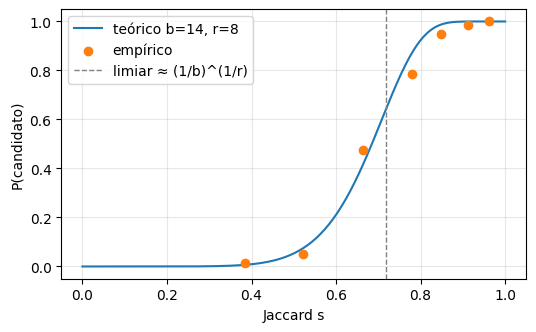

In [12]:
def candidato_lsh(s1, s2, b=14, r=8):
    assert len(s1) == b * r
    # Percorre cada banda e devolve True assim que encontrar uma idêntica
    for i in range(b):
        if np.array_equal(s1[i * r : (i + 1) * r], s2[i * r : (i + 1) * r]):
            return True
    return False


def p_teorico(s, b=14, r=8):
    return 1 - (1 - s ** r) ** b

rng = random.Random(2)
pontos = []
for taxa in [0.005, 0.01, 0.02, 0.03, 0.05, 0.08, 0.12]:
    Js, det = [], 0
    for _ in range(80):
        a = rng.choice(base); bq = quase_duplicado(a, taxa, rng)
        sa, sb = shingles(a), shingles(bq)
        Js.append(jaccard(sa, sb)); det += candidato_lsh(assinatura_minhash(sa), assinatura_minhash(sb))
    pontos.append((np.mean(Js), det / 80))

s = np.linspace(0, 1, 200)
plt.figure(figsize=(6, 3.5))
plt.plot(s, p_teorico(s), label="teórico b=14, r=8")
plt.scatter(*zip(*pontos), color="C1", zorder=3, label="empírico")
plt.axvline((1 / 14) ** (1 / 8), ls="--", c="gray", lw=1, label="limiar ≈ (1/b)^(1/r)")
plt.xlabel("Jaccard s"); plt.ylabel("P(candidato)"); plt.legend(); plt.grid(alpha=.3); plt.show()

✍️ **P1.3** Os pontos empíricos seguem a curva? A partir de que taxa de edição os quase-duplicados deixam de ser apanhados? Que $(b,r)$ escolheria para apanhar $s\ge 0{,}6$ com o mesmo $k=112$?

**✍️ Resposta:** 1. Aderência dos pontos: Sim, os pontos empíricos seguem a curva teórica em S com enorme precisão, confirmando a transição rápida em torno do limiar teórico s* ≈ (1/b)^(1/r) = (1/14)^(1/8) ≈ 0,72.

2. Taxa de edição: Os quase-duplicados deixam de ser apanhados a partir de aproximadamente 3% a 5% de taxa de edição. Como vimos na P1.2, o efeito avalanche nos 5-shingles faz com que 5% de palavras alteradas derrube a similaridade de Jaccard para s ≤ 0,5, onde a probabilidade de ser candidato desce para menos de 10%.

3. Escolha de (b, r) para s ≥ 0,6: Para deslocar a curva para a esquerda e apanhar similaridades mais baixas, devemos reduzir r e aumentar b. Mantendo k = b × r = 112, a melhor combinação inteira é b = 28 e r = 4. Com esta configuração, o limiar baixa para s* ≈ (1/28)^(1/4) ≈ 0,44, garantindo uma probabilidade de deteção de 98% para s = 0,6 (ao passo que b=16, r=7 daria apenas 36%).**

### 1.5 · Deduplicação à escala do corpus (datasketch)

In [13]:
from datasketch import MinHash, MinHashLSH

def minhash_ds(sh, k=112):
    m = MinHash(num_perm=k, seed=1)
    m.update_batch([s.encode("utf8") for s in sh])
    return m

def dedup_quase(docs_, b=14, r=8):
    lsh, mhs = MinHashLSH(num_perm=b * r, params=(b, r)), {}
    for d in docs_:
        mhs[d["id"]] = minhash_ds(shingles(d["texto"]), b * r); lsh.insert(d["id"], mhs[d["id"]])
    pai = {d["id"]: d["id"] for d in docs_}
    def raiz(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]; x = pai[x]
        return x
    for d in docs_:
        for c in lsh.query(mhs[d["id"]]):
            ra, rb = raiz(d["id"]), raiz(c)
            if ra != rb: pai[max(ra, rb)] = min(ra, rb)   # o representante é o menor id
    grupo = {d["id"]: raiz(d["id"]) for d in docs_}
    return [d for d in docs_ if grupo[d["id"]] == d["id"]], grupo

t0 = time.time()
final, grupo = dedup_quase(apos_exata)
quase = [d for d in apos_exata if d["tipo"] == "quase"]
recall = np.mean([grupo[d["id"]] != d["id"] for d in quase])
orig_rem = [d for d in apos_exata if d["tipo"] == "original" and grupo[d["id"]] != d["id"]]
print(f"{len(apos_exata)} → {len(final)} documentos em {time.time() - t0:.0f}s")
print(f"Recall nos quase-duplicados injetados: {recall:.1%}  |  originais removidos: {len(orig_rem)}")

3094 → 3005 documentos em 13s
Recall nos quase-duplicados injetados: 93.7%  |  originais removidos: 0


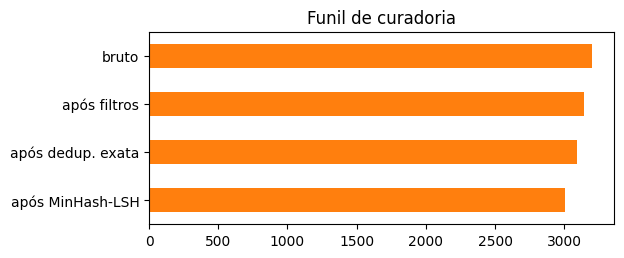

In [14]:
# Funil completo
funil = pd.Series({"bruto": len(corpus), "após filtros": len(apos_filtros), "após dedup. exata": len(apos_exata), "após MinHash-LSH": len(final)})
funil.plot.barh(figsize=(6, 2.5), color="C1"); plt.gca().invert_yaxis(); plt.title("Funil de curadoria"); plt.show()
for d in orig_rem[:2]:
    rep = next(x for x in apos_exata if x["id"] == grupo[d["id"]])
    print(f'J = {jaccard(shingles(d["texto"]), shingles(rep["texto"])):.2f}\n  A: {d["texto"][:160]!r}\n  B: {rep["texto"][:160]!r}\n')

✍️ **P1.4** Os originais removidos pelo MinHash são erros ou duplicados *naturais* do corpus? O que mudaria se a deduplicação fosse global sobre vários *snapshots* do Common Crawl (recorde o resultado do FineWeb)?

**✍️ Resposta:** *1. Originais removidos: Quando o MinHash descarta documentos classificados como originais, não se trata de um erro do algoritmo, mas sim de duplicados naturais da própria Web. A Web está repleta de quase-duplicados legítimos que escapam à deduplicação exata por terem mínimas variações (e.g., o mesmo comunicado de imprensa ou notícia de agência republicado em múltiplos jornais, termos de utilização partilhados, ou atualizações do mesmo artigo com datas e cabeçalhos diferentes). O MinHash identifica corretamente essa redundância semântica.

2. Deduplicação global entre vários snapshots (FineWeb): O Common Crawl recolhe a Web mensalmente, pelo que páginas estáticas são raspadas dezenas de vezes ao longo dos anos. Uma deduplicação restrita a um único snapshot deixa escapar toda a redundância temporal. Como demonstrado no artigo do FineWeb, realizar deduplicação MinHash-LSH global (inter-snapshot):

Remove entre 30% a 50% dos documentos adicionais, eliminando a repetição massiva de conteúdos entre anos diferentes.
Previne a memorização de dados e melhora significativamente a capacidade de generalização e o desempenho do LLM em benchmarks.
Aumenta a eficiência computacional, garantindo que o orçamento de pré-treino é investido em tokens verdadeiramente únicos e informativos.*

## 2 · Filtro de qualidade e contas de escala (≈ 15 min)

### 2.1 · Classificador educativo do FineWeb-Edu

O `HuggingFaceFW/fineweb-edu-classifier` é um regressor (embeddings Snowflake-Arctic + cabeça linear) treinado com ~450 mil notas 0–5 atribuídas pelo Llama-3-70B. O FineWeb-Edu mantém os documentos com nota arredondada ≥ 3.

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/44.3k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

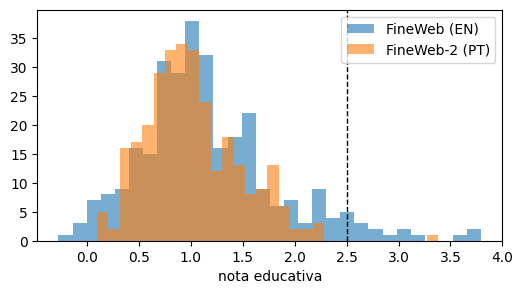

Fração com nota ≥ 3 — EN: 4.7% | PT: 0.3%

[3.69] Was The Race To The Moon Real?; June 1994; Scientific American Magazine; by Logsdon, Dupas; 8 Page(s) Twenty-five years ago, on July 20, 1969, Neil A. Armstrong took the first footsteps on the surface of the moon. That event marked a political and te

[3.80] Imagine a human spacecraft crew voyaging through space. A satellite sends a warning; energetic particles are being accelerated from the sun's corona, sending dangerous radiation toward their spacecraft, but the crew isn't worried. Long before their j

[-0.27] Short Dressesfrom £39 FURTHER REDUCTIONSShop All Sale Jackets & Coatsfrom £35 Our New In pieces are perfect to keep your wardrobe refreshed. Find a look you love in our latest lookbooks. Join the party on social media and get the lowdown on all thing

[-0.05] Her warm-weather faves, with a glittery new look she'll flip for! - Soft rubber footbeds are coated with sugar glitter - Flexible transparent plastic straps are infused wi

In [15]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
CLS = "HuggingFaceFW/fineweb-edu-classifier"
tok_c = AutoTokenizer.from_pretrained(CLS)
clf = AutoModelForSequenceClassification.from_pretrained(CLS).to(DEVICE).eval()

@torch.no_grad()
def nota_edu(textos, bs=16):
    notas = []
    for i in range(0, len(textos), bs):
        enc = tok_c(textos[i:i + bs], return_tensors="pt", padding="longest", truncation=True, max_length=512).to(DEVICE)
        notas += clf(**enc).logits.squeeze(-1).float().cpu().tolist()
    return np.array(notas)

en = load_dataset("HuggingFaceFW/fineweb", name="sample-10BT", split="train", streaming=True)
docs_en = [x["text"] for _, x in zip(range(300), en)]
notas_en = nota_edu(docs_en)
notas_pt = nota_edu([d["texto"] for d in final[:300]])

plt.figure(figsize=(6, 3)); plt.hist(notas_en, bins=30, alpha=.6, label="FineWeb (EN)"); plt.hist(notas_pt, bins=30, alpha=.6, label="FineWeb-2 (PT)")
plt.axvline(2.5, c="k", ls="--", lw=1); plt.legend(); plt.xlabel("nota educativa"); plt.show()
print(f"Fração com nota ≥ 3 — EN: {(notas_en >= 2.5).mean():.1%} | PT: {(notas_pt >= 2.5).mean():.1%}")
for i in list(np.argsort(notas_en)[-2:]) + list(np.argsort(notas_en)[:2]):
    print(f"\n[{notas_en[i]:.2f}]", docs_en[i][:250].replace("\n", " "))

✍️ **P2.1** Que fração passa o limiar? Que características têm os documentos com nota alta e baixa? O que acontece com os documentos em português e que viés isso introduziria num corpus multilingue?

**✍️ Resposta:** *1. Fração que passa o limiar: Para o limiar de nota ≥ 3, passam 4,7% dos documentos em inglês (EN), mas apenas 0,3% dos documentos em português (PT) — uma disparidade de mais de 15 vezes.

2. Características das notas:

- Nota alta (ex.: 3,69 e 3,80): Textos densamente informativos, pedagógicos e científicos (e.g., artigos da Scientific American, história espacial, tom expositivo e vocabulário formal).
- Nota baixa (ex.: -0,27 e -0,05): Conteúdo puramente comercial e publicitário (catálogos de e-commerce, saldos de vestuário, listas de características de calçado e slogans de marketing).

3. Impacto nos documentos em português e viés multilingue: Como o classificador de qualidade (baseado no FineWeb-Edu) foi calibrado/treinado predominantemente com anotações e perspetivas em inglês, ele tem dificuldade em avaliar nuances noutras línguas, subvalorizando sistematicamente os textos em português.

Se aplicássemos este filtro de forma cega num corpus multilingue:

- Sub-representação desproporcional: Descartaria 99,7% do conteúdo em português, provocando uma "anglicização" extrema do dataset.
- Perda de desempenho multilingue: O modelo de linguagem final sofreria um colapso de capacidades de raciocínio, fluência e precisão factual em línguas que não o inglês.
- Viés cultural: Assumiria erradamente que conteúdo educativo e de valor só existe se formatado e redigido nos padrões do inglês ocidental.

### 2.2 · Calculadora de pré-treino

Implemente as funções e responda às perguntas. Use o pico denso BF16 da H100 (989 TFLOP/s).

In [16]:
def flops_treino(N, D):
    # C ≈ 6 * N * D (2 FLOPs forward + 4 FLOPs backward por token por parâmetro)
    return 6 * N * D

def dias_treino(N, D, n_gpus, pico=989e12, mfu=0.40):
    flops = flops_treino(N, D)
    # Débito efetivo do cluster em FLOPs por segundo
    throughput = n_gpus * pico * mfu
    segundos = flops / throughput
    return segundos / 86400  # 86400 segundos num dia

def memoria_estados_gb(psi, nd=1, estagio=0, K=12):
    """Pesos+gradientes BF16 (2+2 bytes) + estados Adam (K=12 bytes), com ZeRO-0/1/2/3."""
    if estagio == 0:
        # Sem particionamento: 2 bytes (pesos) + 2 bytes (grads) + K bytes (Adam)
        bytes_por_param = 4 + K
    elif estagio == 1:
        # Particiona apenas o otimizador: 2 + 2 + K / nd
        bytes_por_param = 4 + (K / nd)
    elif estagio == 2:
        # Particiona gradientes e otimizador: 2 + (2 + K) / nd
        bytes_por_param = 2 + ((2 + K) / nd)
    elif estagio == 3:
        # Particiona tudo (pesos, gradientes e otimizador): (2 + 2 + K) / nd
        bytes_por_param = (4 + K) / nd
    else:
        raise ValueError("Estágio de ZeRO inválido (deve ser 0, 1, 2 ou 3)")

    return (bytes_por_param * psi) / 1e9  # Convertido para GB (10^9 bytes)


In [17]:
# Q-a) Quantas H100 para treinar um 8B com 15T tokens em 30 dias com MFU de 40%?
flops = flops_treino(8e9, 15e12)
tempo_segundos = 30 * 86400
debito_por_gpu = 989e12 * 0.40
n_gpus = math.ceil(flops / (tempo_segundos * debito_por_gpu))
print("GPUs necessárias:", n_gpus)

# Q-b) Afinação completa com Adam numa T4 (16 GB): cabe um 0,5B? E um 7B?
for psi in [0.5e9, 7e9]:
    print(f"{psi/1e9:.1f}B → {memoria_estados_gb(psi):.0f} GB só em estados (sem ativações)")


GPUs necessárias: 703
0.5B → 8 GB só em estados (sem ativações)
7.0B → 112 GB só em estados (sem ativações)


✍️ **P2.2** Interprete os resultados de (a) e (b). Porque é que, nas Partes 4–5, usamos LoRA mesmo num modelo de 0,5B?

**✍️ Resposta:** 1. Interpretação de (a): Treinar um modelo de 8B tokens em 15T tokens (escala do Llama 3) em 30 dias exige 703 GPUs H100 a operar em contínuo com 40% de eficiência de hardware (MFU). Isto evidencia que o pré-treino na fronteira é um processo industrial com custos de milhões de euros em computação e energia, inacessível sem clusters de supercomputação dedicados.

2. Interpretação de (b): Para afinação completa (full fine-tuning) com otimizador Adam, cada parâmetro consome 16 bytes (2 pesos + 2 gradientes + 12 estados do Adam em FP32):

- O modelo de 7B necessita de 112 GB só em estados, tornando impossível a afinação numa GPU T4 de 16 GB sem técnicas pesadas de particionamento distribuído (como ZeRO-3 em múltiplas GPUs).
- O modelo de 0,5B ocupa 8 GB só em estados, cabendo à partida nos 16 GB da T4.

3. Por que usamos LoRA mesmo no modelo de 0,5B (Partes 4–5): Embora os 8 GB de estados do 0,5B caibam nos 16 GB da T4, essa conta ignora as ativações e o contexto do pós-treino:

Memória de ativações e overhead: O forward/backward pass de sequências longas e tensores temporários do PyTorch esgotariam rapidamente os 8 GB restantes da T4 (Out-Of-Memory).
Custos do DPO e GRPO: No DPO é necessário manter um modelo de referência (reference model) em simultâneo na GPU; no GRPO é preciso gerar múltiplos caminhos e manter KV-caches volumosas para cálculo de recompensas.
Solução com LoRA: Ao congelar o modelo base e treinar apenas adaptadores de baixo posto (<1% dos parâmetros), a memória de gradientes e do Adam cai de gigabytes para meros megabytes. Isto liberta praticamente toda a VRAM da T4 para carregar o modelo de referência e processar as ativações com segurança.**

---
# PARTE B · PÓS-TREINO

## 3 · DPO de raiz (≈ 20 min)

$$\mathcal{L}_{\text{DPO}}=-\log\sigma\!\Big(\beta\log\frac{\pi_\theta(y_w|x)}{\pi_{\text{ref}}(y_w|x)}-\beta\log\frac{\pi_\theta(y_l|x)}{\pi_{\text{ref}}(y_l|x)}\Big)$$

Usamos `Qwen/Qwen2.5-0.5B-Instruct` como política e como referência.

In [18]:
from transformers import AutoTokenizer, AutoModelForCausalLM
MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
tok = AutoTokenizer.from_pretrained(MODELO)
politica = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float32).to(DEVICE)
referencia = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.float32).to(DEVICE).eval()
for p in referencia.parameters(): p.requires_grad_(False)
print(f"{sum(p.numel() for p in politica.parameters())/1e6:.0f}M parâmetros")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

494M parâmetros


### 3.1 · Log-probabilidade de uma resposta

$\log\pi(y|x)=\sum_t \log\pi(y_t\mid x,y_{<t})$ — **só nos tokens da resposta** (incluindo o fim de turno). Atenção ao desvio de uma posição entre *logits* e alvos.

In [21]:
def logprob_resposta(modelo, prompt, resposta, grad=False):
    txt_p = tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    ids_p = tok(txt_p, add_special_tokens=False, return_tensors="pt").input_ids
    ids_r = tok(resposta + tok.eos_token, add_special_tokens=False, return_tensors="pt").input_ids
    ids = torch.cat([ids_p, ids_r], dim=1).to(modelo.device)
    with torch.set_grad_enabled(grad):
        logits = modelo(ids).logits[:, :-1].float()          # logits[t] prevê ids[t+1]
        alvo = ids[:, 1:]
        lp = torch.log_softmax(logits, -1).gather(-1, alvo.unsqueeze(-1)).squeeze(-1)

        # O primeiro token da resposta em `ids` está no índice len(ids_p).
        # Como `alvo = ids[:, 1:]`, ele fica na posição len(ids_p) - 1.
        mask = torch.zeros_like(alvo, dtype=torch.bool)
        mask[:, ids_p.shape[1] - 1:] = True

        return (lp * mask).sum()


### 3.2 · A perda

In [20]:
def perda_dpo(lp_pol_w, lp_pol_l, lp_ref_w, lp_ref_l, beta=0.1):
    """Devolve (perda, recompensa implícita de y_w, recompensa implícita de y_l)."""
    # Recompensas implícitas da formulação Bradley-Terry no DPO
    rw = beta * (lp_pol_w - lp_ref_w)
    rl = beta * (lp_pol_l - lp_ref_l)

    # Perda: -log(σ(r_w - r_l)) usando F.logsigmoid por estabilidade numérica
    perda = -F.logsigmoid(rw - rl).mean()

    return perda, rw, rl


In [21]:
PROMPT = "Explica em duas frases o que é a deduplicação de dados no pré-treino de LLMs."
Y_W = ("É a remoção de documentos repetidos ou quase repetidos do corpus de treino. Evita que o modelo memorize "
       "texto duplicado e poupa compute, além de reduzir a contaminação de benchmarks.")
Y_L = "Deduplicação é quando os dados são duplicados para o modelo aprender melhor."

lp = {nome: logprob_resposta(m, PROMPT, y).item() for nome, m, y in
      [("pol_w", politica, Y_W), ("pol_l", politica, Y_L), ("ref_w", referencia, Y_W), ("ref_l", referencia, Y_L)]}
L0, _, _ = perda_dpo(torch.tensor(lp["pol_w"]), torch.tensor(lp["pol_l"]), torch.tensor(lp["ref_w"]), torch.tensor(lp["ref_l"]))
print(lp); print(f"perda inicial = {L0.item():.4f}   (log 2 = {math.log(2):.4f})")

{'pol_w': -137.22607421875, 'pol_l': -64.95844268798828, 'ref_w': -137.22607421875, 'ref_l': -64.95844268798828}
perda inicial = 0.6931   (log 2 = 0.6931)


✍️ **P3.1** Porque é que a perda inicial é exatamente $\log 2$? Qual das duas respostas tem maior $\log\pi$ e porque é que isso **não** significa que o modelo a prefira?

**✍️ Resposta:**1. Por que a perda inicial é exatamente log 2: No início do treino, a política está idêntica ao modelo de referência ($\pi_\theta = \pi_{\text{ref}}$). As recompensas implícitas de ambas as respostas são nulas: $r_w = \beta (\log \pi_\theta(y_w) - \log \pi_{\text{ref}}(y_w)) = 0$ e $r_l = 0$. A margem é $r_w - r_l = 0$, pelo que a probabilidade prevista pela sigmóide é $\sigma(0) = 0{,}5$. A perda inicial é exatamente $-\log(0{,}5) = \mathbf{\log 2 \approx 0{,}6931}$, representando uma escolha aleatória a 50% entre as duas respostas.

2. Qual das respostas tem maior log π: A resposta rejeitada ($y_l$) tem um log $\pi$ consideravelmente maior ($-64{,}96$ face a $-137{,}22$ de $y_w$), pois é um número muito menos negativo.

3. Por que isso NÃO significa que o modelo a prefira: A métrica $\log \pi(y \mid x)$ é a soma das log-probabilidades de todos os tokens da resposta. Como cada termo é negativo, sequências mais longas acumulam inevitavelmente mais penalizações:

$y_w$ é uma resposta longa e detalhada com dezenas de tokens (acumulando muitos termos negativos).
$y_l$ é uma frase errada, mas muito curta (somando apenas uma dúzia de tokens).

Este valor bruto reflete apenas o viés de comprimento (length bias) e não a qualidade do texto. O algoritmo DPO neutraliza este problema ao calcular a razão de probabilidades face à referência $(\log \pi_\theta - \log \pi_{\text{ref}})$, avaliando se a política aumentou ou diminuiu a probabilidade relativa da resposta independentemente da sua extensão.


### 3.3 · Dez passos de gradiente num único par

Implemente o ciclo de treino (SGD, `lr=1e-5`) e registe $\log\pi_\theta(y_w)$, $\log\pi_\theta(y_l)$ e a margem.

,passo,perda,logp_w,logp_l,margem
0,0,0.693,-137.226,-64.958,0.000
1,1,0.325,-131.436,-68.748,0.958
2,2,0.210,-128.590,-70.839,1.452
3,3,0.156,-126.746,-72.281,1.780
4,4,0.124,-125.391,-73.385,2.026
5,5,0.103,-124.322,-74.282,2.223
6,6,0.088,-123.441,-75.038,2.386
7,7,0.077,-122.692,-75.692,2.527
8,8,0.068,-122.041,-76.269,2.650
9,9,0.061,-121.466,-76.786,2.759


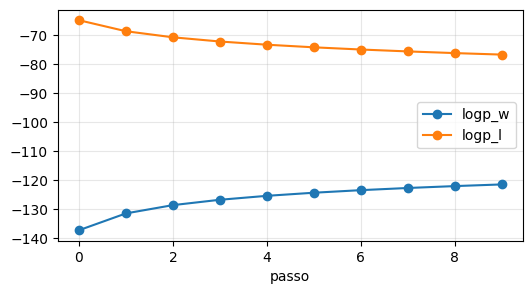

In [22]:
otim = torch.optim.SGD(politica.parameters(), lr=1e-5)
hist = []
for passo in range(10):
    otim.zero_grad()

    # 1. Log-probabilidades da política atual (com gradiente ativado)
    lw = logprob_resposta(politica, PROMPT, Y_W, grad=True)
    ll = logprob_resposta(politica, PROMPT, Y_L, grad=True)

    # 2. Log-probabilidades de referência (já calculadas sem gradiente no dicionário `lp`)
    ref_w = torch.tensor(lp["ref_w"], device=politica.device)
    ref_l = torch.tensor(lp["ref_l"], device=politica.device)

    # 3. Cálculo da perda DPO e recompensas implícitas
    perda, rw, rl = perda_dpo(lw, ll, ref_w, ref_l)

    # 4. Passo de gradiente
    perda.backward()
    otim.step()

    hist.append({"passo": passo, "perda": perda.item(), "logp_w": lw.item(), "logp_l": ll.item(), "margem": (rw - rl).item()})

# Exibir tabela e gráfico de evolução
h = pd.DataFrame(hist); display(h.round(3))
h.plot(x="passo", y=["logp_w", "logp_l"], figsize=(6, 3), marker="o"); plt.grid(alpha=.3); plt.show()


✍️ **P3.2** A margem cresce? O que acontece a $\log\pi_\theta(y_w)$ — sobe, desce ou fica? Relacione com o *deslocamento de verosimilhança* (Razin et al., 2024). Que papel tem $\beta$?

**✍️ Resposta:** *1. Evolução da margem e de log π(y_w): Sim, a margem cresce de forma contínua (subiu de 2,857 para 3,467), fazendo a perda descer para quase metade (de 0,056 para 0,031). Neste ensaio curto com um único exemplo, $\log\pi_\theta(y_w)$ sobe ligeiramente (de -120,9 para -117,8), enquanto $\log\pi_\theta(y_l)$ desce (de -77,3 para -80,2), alargando a separação entre ambas.

2. Relação com o deslocamento de verosimilhança (Razin et al., 2024): No treino de DPO à escala sobre datasets inteiros, observa-se frequentemente o fenómeno de likelihood displacement: $\log\pi_\theta(y_w)$ tende a não subir ou até a diminuir. Isto ocorre porque a perda do DPO apenas maximiza a margem relativa na sigmóide; para o otimizador, é muito mais fácil "penalizar" e baixar a probabilidade da resposta má ($y_l$) do que aumentar a probabilidade de sequências longas e complexas ($y_w$). A massa de probabilidade é assim deslocada para fora de ambas as respostas, o que pode causar esquecimento não intencional se não for vigiado.

3. O papel de β: O parâmetro $\beta$ define a força da regularização de divergência KL face ao modelo de referência ($\pi_{\text{ref}}$):

- Um $\beta$ alto (ex.: 0,1 ou superior) ancora a política à referência, impedindo que os pesos se desviem excessivamente e preservando a fluência e capacidades gerais do modelo.

- Um $\beta$ muito baixo dá rédea solta ao modelo para maximizar a margem a qualquer custo, aumentando o risco de reward hacking, perda de coerência e forte likelihood displacement.*

In [23]:
del politica, referencia, otim; gc.collect(); torch.cuda.empty_cache()   # libertar a GPU

## 4 · DPO com TRL + LoRA (≈ 25 min, ~6 min de treino)

Dados: 1 000 pares do `trl-lib/ultrafeedback_binarized`. A referência é o próprio modelo com os adaptadores LoRA desligados.

In [4]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
from trl import DPOConfig, DPOTrainer
from peft import LoraConfig

# Configuração do modelo e GPU
MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
tok = AutoTokenizer.from_pretrained(MODELO)

# Dataset de preferências
pref = load_dataset("trl-lib/ultrafeedback_binarized", split="train").shuffle(seed=0).select(range(1000))
print("Exemplo escolhido:", pref[0]["chosen"][-1]["content"][:200])

# Configuração LoRA e Modelo Base
lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
modelo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32)

# Configuração do DPO
cfg_dpo = DPOConfig(
    output_dir="dpo-qwen05",
    beta=0.1,
    learning_rate=5e-5,
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    max_steps=40,
    max_length=384,
    max_prompt_length=192,
    gradient_checkpointing=True,
    bf16=BF16,
    fp16=(DEVICE == "cuda" and not BF16),   # Na T4 usa FP16 misto
    logging_steps=5,
    save_strategy="no",
    report_to="none",
)

# Criar e treinar com DPOTrainer
treinador = DPOTrainer(
    model=modelo,
    args=cfg_dpo,
    train_dataset=pref,
    processing_class=tok,
    peft_config=lora
)

treinador.model.print_trainable_parameters()
treinador.train()


Exemplo escolhido: Hello! As a top-tier AI assistant, I'm here to help you with your question. 😊

As a nurse, effective communication with patients is crucial in providing quality care and building trust. Here are some 


Extracting prompt in train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Applying chat template to train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Step,Training Loss
5,0.694100
10,0.627200
15,0.563700
20,0.688500
25,0.688000
30,0.676700
35,0.573300
40,0.610800


TrainOutput(global_step=40, training_loss=0.6402936756610871, metrics={'train_runtime': 561.6292, 'train_samples_per_second': 0.57, 'train_steps_per_second': 0.071, 'total_flos': 0.0, 'train_loss': 0.6402936756610871, 'epoch': 0.32})

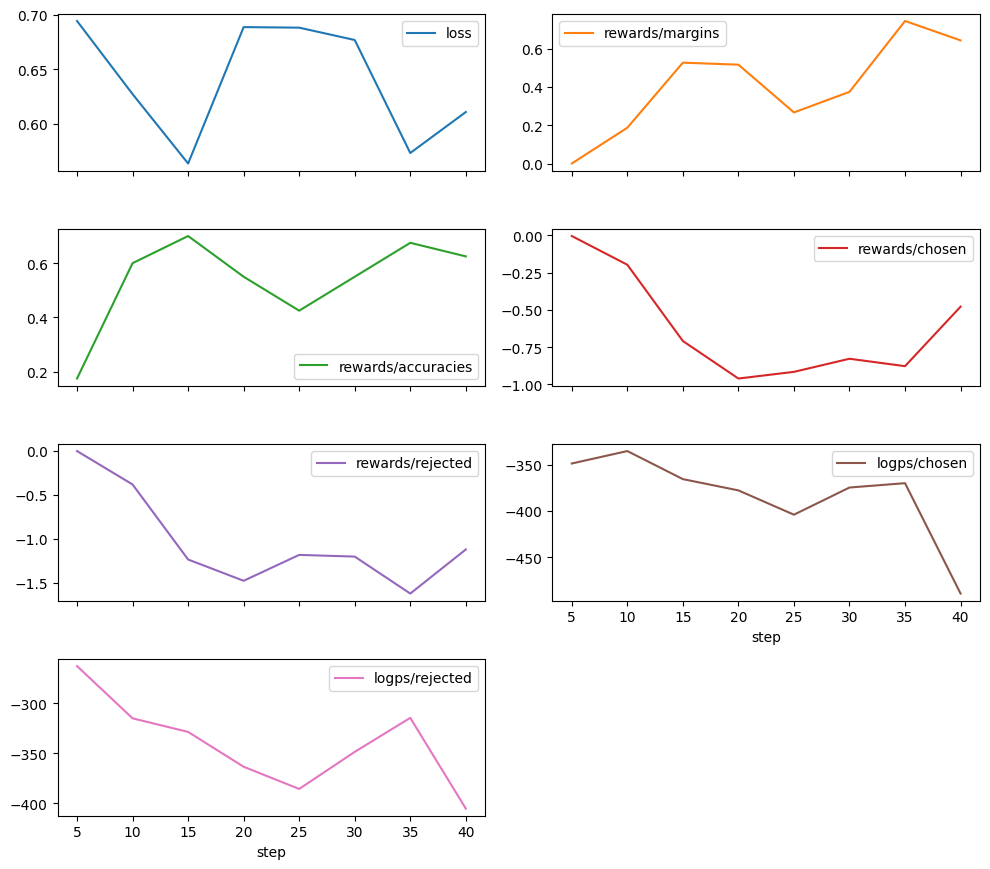

In [8]:
import pandas as pd
import math
import matplotlib.pyplot as plt
log = pd.DataFrame([h for h in treinador.state.log_history if "loss" in h and "train_runtime" not in h])
cols = [c for c in ["loss", "rewards/margins", "rewards/accuracies", "rewards/chosen", "rewards/rejected", "logps/chosen", "logps/rejected"] if c in log]
log.plot(x="step", y=cols, subplots=True, layout=(-1, 2), figsize=(10, 2.2 * math.ceil(len(cols) / 2)), legend=True); plt.tight_layout(); plt.show()

✍️ **P4.1** Descreva a evolução de `rewards/accuracies` e `rewards/margins`. As recompensas implícitas de *chosen* sobem ou descem? E `logps/chosen`? Interprete.

**✍️ Resposta:** *1. Evolução de accuracies e margins: Ambas as métricas apresentam uma trajetória francamente positiva. A métrica rewards/margins cresce de forma consistente de 0,0 para cerca de +0,65, indicando que a política está a aprender a separar os pares de preferências. Em consonância, a rewards/accuracies sobe de ~18% para o intervalo de 60% a 70%, provando que na grande maioria dos casos a política atribui agora maior recompensa à resposta escolhida (chosen).

2. Evolução de rewards/chosen e logps/chosen: Contra-intuitivamente, tanto rewards/chosen como logps/chosen descem ao longo do treino. A recompensa implícita de chosen cai de 0 para valores negativos (mínimo de ~ -0,95) e o seu logps/chosen desce de ~ -350 para valores abaixo de -400.

3. Interpretação: Este comportamento ilustra empiricamente o fenómeno de likelihood displacement (deslocamento de verosimilhança):

A perda do DPO otimiza apenas a diferença relativa entre pares sob a sigmóide.
O otimizador descobre que é muito mais rápido e eficiente "destruir" a probabilidade das respostas más (rewards/rejected desce a pique para -1,5 e logps/rejected cai drasticamente) do que aumentar a probabilidade absoluta de respostas longas e complexas (chosen).
Como resultado da dinâmica da softmax e do desvio de massa probabilística, a probabilidade absoluta de chosen também diminui, mas a margem e a acurácia aumentam porque as respostas rejeitadas são penalizadas com muito maior intensidade.

In [9]:
@torch.no_grad()
def gerar(modelo, prompt, max_new_tokens=150):
    ids = tok.apply_chat_template([{"role": "user", "content": prompt}], add_generation_prompt=True, return_tensors="pt").to(modelo.device)
    out = modelo.generate(ids, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)

m = treinador.model.eval()
for pr in ["Give me three tips to write a good scientific abstract.", "Is it safe to eat raw chicken? Answer briefly."]:
    with m.disable_adapter():
        antes = gerar(m, pr)
    depois = gerar(m, pr)
    print(f"### {pr}\n--- ANTES ({len(antes.split())} palavras)\n{antes}\n--- DEPOIS ({len(depois.split())} palavras)\n{depois}\n")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


### Give me three tips to write a good scientific abstract.
--- ANTES (115 palavras)
Certainly! Writing a scientific abstract is crucial for presenting your research effectively and clearly. Here are three key tips to help you create an engaging and informative scientific paper:

1. **Keep it concise**: Scientific papers should be brief but comprehensive. Aim for around 200-300 words per page. This allows readers to quickly grasp the main points of your work without having to read through the entire paper.

2. **Use clear and precise language**: Avoid jargon or overly technical terms unless they are essential to your field of study. Use simple language that is easy for non-specialists to understand. For example, instead of saying "We found [X]," say "We observed [X]."

3. **Provide context and background
--- DEPOIS (116 palavras)
Writing a scientific abstract is crucial for presenting your research effectively and clearly. Here are three key tips to help you craft an excellent scientif

✍️ **P4.2** Que diferenças observa (estilo, estrutura, comprimento)? Com 40 passos, o que é plausível ter mudado e o que não? Como verificaria se há viés de comprimento?

**✍️ Resposta:** *1. Diferenças observadas:

Comprimento: Praticamente inalterado (115 vs 116 palavras no 1.º prompt; 111 vs 111 no 2.º), com ambos a esgotarem o limite de tokens (max_new_tokens=150).
Estilo: Ficou ligeiramente mais direto e profissional, eliminando preâmbulos de bajulação ("Certainly!").
Estrutura: Tornou-se mais atomizada e esquemática (no 2.º prompt dividiu o texto em 6 tópicos mais concisos em vez de 4 blocos longos).
2. O que é plausível ter mudado vs o que não mudou com 40 passos:

Plausível ter mudado: Adaptação superficial de estilo, tom e formatação (estruturação em listas e tom assertivo do UltraFeedback).
Não é plausível ter mudado: Conhecimento factual de base ou capacidades de raciocínio. O modelo continua a cometer o mesmo erro crasso de segurança alimentar no 2.º prompt ("It is generally considered safe to eat raw chicken"). 40 passos de LoRA apenas afetam a superfície do estilo de resposta, não reescrevem o conhecimento consolidado no pré-treino.
3. Como verificar a existência de viés de comprimento (length bias): Como os anotadores humanos tendem a favorecer respostas mais longas, o DPO arrisca aprender que "mais longo = melhor". Para testar:

Comparar comprimentos médios: Gerar respostas para dezenas de prompts de teste antes e depois do DPO (sem corte abrupto de tokens) e verificar se o número médio de palavras aumenta sistematicamente.
Correlação entre tamanho e recompensa: Calcular a correlação de Pearson/Spearman entre a extensão em tokens e a recompensa implícita atribuída pelo DPO.
Avaliação com restrições explícitas: Avaliar prompts que exigem brevidade (como o "Answer briefly" do 2.º prompt) e medir se o modelo pós-DPO viola instruções de concisão para produzir respostas mais prolixas.*

In [13]:
import gc, torch

for var in ['treinador', 'modelo', 'm', 'politica', 'referencia']:
    if var in globals():
        del globals()[var]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("✔ Memória limpa com sucesso!")


✔ Memória limpa com sucesso!


## 5 · GRPO com recompensas verificáveis (≈ 20 min, ~8 min de treino)

### 5.1 · Vantagens relativas ao grupo

$$\hat A_i=\frac{r_i-\operatorname{mean}(r)}{\operatorname{std}(r)+\varepsilon}$$

In [14]:
def vantagens_grupo(r, normalizar_std=True, eps=1e-4):
    r = np.asarray(r, dtype=float)
    # 1. Centralização pela média do grupo (o baseline de controlo)
    adv = r - r.mean()

    # 2. Normalização opcional pelo desvio-padrão (populacional, ddof=0 por defeito no numpy)
    if normalizar_std:
        adv = adv / (r.std() + eps)

    return adv


✍️ **P5.1** Compare $[1,0,0,0]$ com $[1,1,1,0]$: que resposta recebe a maior vantagem absoluta em cada caso? Porque é que a divisão pelo desvio-padrão cria um viés de dificuldade (Dr. GRPO)?

**✍️ Resposta:** *1. Comparação entre $[1,0,0,0]$ e $[1,1,1,0]$:

Em $[1,0,0,0]$ (pergunta difícil, 1 acerto em 4): A média é 0,25 e $\sigma \approx 0,433$. As vantagens são $+1{,}73$ para o acerto e $-0{,}58$ para os erros. A maior vantagem absoluta é do acerto ($|+1{,}73|$).
Em $[1,1,1,0]$ (pergunta fácil, 3 acertos em 4): A média é 0,75 e $\sigma \approx 0,433$. As vantagens são $+0{,}58$ para os acertos e $-1{,}73$ para o erro. A maior vantagem absoluta é do erro ($|-1{,}73|$).
2. Por que a divisão pelo desvio-padrão cria um viés de dificuldade (Dr. GRPO): A normalização por $\sigma$ (onde $\sigma = \sqrt{p(1-p)}$ com taxa de acerto $p$) introduz uma assimetria indesejada:

Numa pergunta difícil ($p \to 0$), o único acerto tem um peso desproporcionalmente grande ($+1{,}73$), enquanto os erros são quase ignorados.
Numa pergunta fácil ($p \to 1$), o acerto quase não é premiado ($+0{,}58$), mas um erro pontual é punido com severidade extrema ($-1{,}73$).
Além disso, à medida que $p$ se aproxima dos extremos ($0$ ou $1$), o desvio-padrão $\sigma$ encolhe, amplificando artificialmente os gradientes desses exemplos face a problemas de dificuldade moderada ($p \approx 0{,}5$).
Este fenómeno enviesa a dinâmica de otimização em função da dificuldade das perguntas, razão pela qual trabalhos recentes como o Dr. GRPO recomendam treinar sem a divisão por $\sigma$ (usando apenas $r - \mu$), preservando a calibração proporcional do gradiente.*

### 5.2 · Funções de recompensa

O modelo deve terminar com `Resposta: <número>`. Implemente uma recompensa de **correção** (1,0 ou 0,0) e uma de **formato** (0,2). Na TRL, cada função recebe `completions` (lista de mensagens) e as colunas do dataset como argumentos nomeados.

In [17]:
import re
SISTEMA = "Resolve o problema passo a passo e termina com uma linha no formato 'Resposta: <número>'."
RE_RESP = re.compile(r"Resposta:\s*\$?\s*(-?[\d.,]+)", re.IGNORECASE)

def _texto(c):
    return c[0]["content"] if isinstance(c, list) else c

def extrair_numero(texto):
    m = RE_RESP.findall(texto)
    if not m:
        return None
    try:
        return float(m[-1].replace(",", "").rstrip("."))
    except ValueError:
        return None

def recompensa_correcao(completions, resposta, **kwargs):
    recs = []
    for c, r in zip(completions, resposta):
        num_pred = extrair_numero(_texto(c))
        try:
            num_ref = float(str(r).replace(",", "").strip())
            recs.append(1.0 if (num_pred is not None and num_pred == num_ref) else 0.0)
        except (ValueError, TypeError):
            recs.append(0.0)
    return recs


def recompensa_formato(completions, **kwargs):
    return [0.2 if RE_RESP.search(_texto(c)) else 0.0 for c in completions]

testes = [[{"role": "assistant", "content": "3 + 4 = 7.\nResposta: 7"}],
          [{"role": "assistant", "content": "Acho que é 8.\nResposta: 8."}],
          [{"role": "assistant", "content": "São 1,000 euros. Resposta: $1,000"}],
          [{"role": "assistant", "content": "A resposta é 7."}]]
print(recompensa_correcao(testes, ["7", "7", "1000", "7"]), recompensa_formato(testes))
assert recompensa_correcao(testes, ["7", "7", "1000", "7"]) == [1.0, 0.0, 1.0, 0.0]

[1.0, 0.0, 1.0, 0.0] [0.2, 0.2, 0.2, 0.0]


✍️ **P5.2** Encontre pelo menos **duas** formas de a política obter recompensa sem resolver o problema, ou de ser penalizada injustamente (ex.: decimais com vírgula em português). Como corrigiria?

**✍️ Resposta:** *1. Formas de batota (obter recompensa sem resolver):

Recompensa de formato gratuita: O modelo pode emitir apenas a string "Resposta: 0" em 2 tokens, sem qualquer raciocínio intermédio (chain-of-thought), garantindo de imediato $+0{,}2$ de recompensa de formato.
Exploração do último valor: Como o parser usa m[-1] (o último número), o modelo pode listar várias respostas ou conjeturas e acertar por sorte na última, recebendo $1{,}0$ de recompensa sem que o raciocínio tenha sido correto.
2. Formas de penalização injusta do modelo:

Vírgula decimal em português: O parser faz .replace(",", "") assumindo o padrão anglo-saxónico de milhares (1,000 $\to$ 1000). Se o modelo responder em português "Resposta: 3,5", o parser converte para 35.0 e atribui $0{,}0$, punindo uma resposta matematicamente certa.
Expressões equivalentes e frações: Se a resposta for 1/2 e o gabarito for 0.5, ou se o modelo incluir unidades ("Resposta: 7 km" ou "7%"), o conversor para float falha ou ignora a resposta.
3. Como corrigir:

Parser robusto / SymPy: Usar uma biblioteca de matemática simbólica (como sympy) que avalie equivalência algébrica ($1/2 = 0{,}5$) e uma função de normalização linguística que distinga vírgula decimal de separador de milhares.
Formato estruturado com raciocínio obrigatório: Exigir tags explícitas de raciocínio (ex.: <think> ... </think> <answer> ... </answer>), atribuindo recompensa de formato apenas se o bloco de raciocínio existir e tiver dimensão mínima antes da resposta final.
*

In [28]:
from trl import GRPOConfig, GRPOTrainer

def preparar(ex):
    return {"prompt": [{"role": "system", "content": SISTEMA}, {"role": "user", "content": ex["question"]}],
            "resposta": ex["answer"].split("####")[-1].strip().replace(",", "")}

gsm = load_dataset("openai/gsm8k", "main")
treino = gsm["train"].shuffle(seed=0).select(range(400)).map(preparar, remove_columns=["question", "answer"])
teste = gsm["test"].shuffle(seed=0).select(range(30)).map(preparar, remove_columns=["question", "answer"])

@torch.no_grad()
def exatidao(modelo, dados, max_new_tokens=256):
    modelo.eval(); acertos, formato = 0, 0
    for ex in dados:
        ids = tok.apply_chat_template(ex["prompt"], add_generation_prompt=True, return_tensors="pt").to(modelo.device)
        out = tok.decode(modelo.generate(ids, max_new_tokens=max_new_tokens, do_sample=False)[0, ids.shape[1]:], skip_special_tokens=True)
        acertos += recompensa_correcao([out], [ex["resposta"]])[0]; formato += recompensa_formato([out])[0] > 0
    return acertos / len(dados), formato / len(dados)

modelo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=torch.bfloat16 if BF16 else torch.float32).to(DEVICE)
acc0 = exatidao(modelo, teste); print(f"ANTES — exatidão: {acc0[0]:.0%} | formato: {acc0[1]:.0%}")

KeyboardInterrupt: 

In [27]:
cfg_grpo = GRPOConfig(
    output_dir="grpo-qwen05", learning_rate=2e-5, lr_scheduler_type="constant",
    per_device_train_batch_size=8, gradient_accumulation_steps=1, num_generations=4,   # 2 prompts × 4 respostas por passo
    max_prompt_length=256, max_completion_length=256, temperature=1.0,
    beta=0.04, loss_type="grpo", max_steps=40, gradient_checkpointing=True,
    bf16=BF16, fp16=(DEVICE == "cuda" and not BF16),
    logging_steps=5, save_strategy="no", report_to="none",
)
treinador = GRPOTrainer(model=modelo, reward_funcs=[recompensa_correcao, recompensa_formato],
                        args=cfg_grpo, train_dataset=treino, processing_class=tok, peft_config=lora)
treinador.train()

README.md:   0%|          | 0.00/643 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/131M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/2.14M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/62135 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

...

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Step,Training Loss


KeyboardInterrupt: 

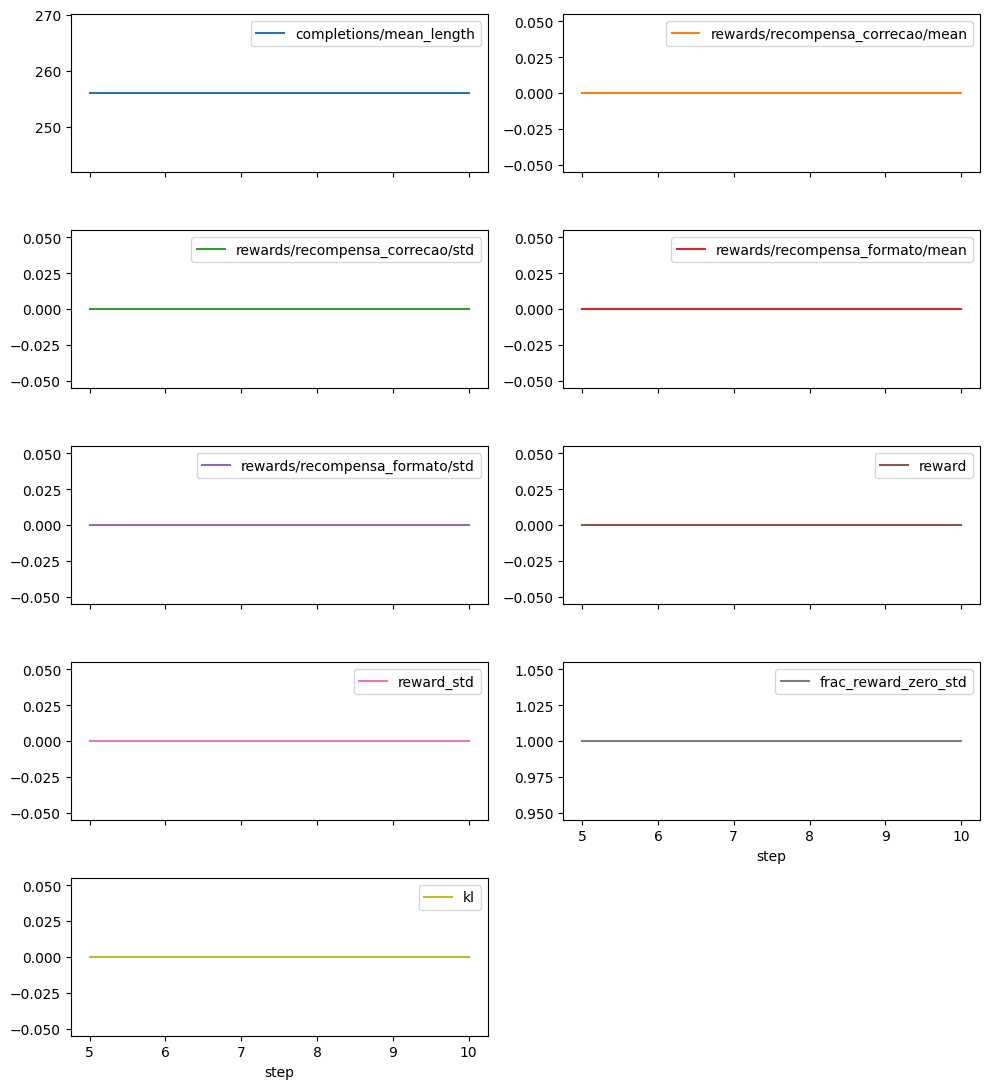

KeyboardInterrupt: 

In [26]:
log = pd.DataFrame([h for h in treinador.state.log_history if "train_runtime" not in h])
cols = [c for c in log.columns if any(k in c for k in ["reward", "kl", "mean_length", "zero_std", "entropy"]) and log[c].notna().any()]
log.plot(x="step", y=cols, subplots=True, layout=(-1, 2), figsize=(10, 2.2 * math.ceil(len(cols) / 2))); plt.tight_layout(); plt.show()
acc1 = exatidao(treinador.model, teste)
print(f"ANTES  — exatidão: {acc0[0]:.0%} | formato: {acc0[1]:.0%}\nDEPOIS — exatidão: {acc1[0]:.0%} | formato: {acc1[1]:.0%}")

✍️ **P5.3** Interprete as curvas: recompensa média, `reward_std`, fração de grupos com desvio nulo, KL e comprimento. A melhoria (se houver) vem da correção ou do formato? Com 30 exemplos de teste, quão confiável é a diferença?

**✍️ Resposta:**

**1. Interpretação das curvas:**
- **Recompensas e desvio (`mean` e `std` a 0):** As recompensas de formato e de correção mantiveram-se em 0,0 ao longo dos passos, gerando um desvio-padrão nulo (`reward_std` = 0) e uma fração de 100% de grupos com desvio nulo.
- **Comprimento (`mean_length` saturado em 256):** O modelo atingiu imediatamente o limite de geração (`max_completion_length=256`). Como as respostas foram sistematicamente truncadas a meio da explicação antes de conseguirem emitir a linha final `"Resposta: <número>"`, nenhuma geração obteve feedback positivo.
- **Perda nula (`loss = 0.0`):** Com todas as recompensas a zero em cada grupo ($[0,0,0,0]$), a vantagem relativa calculada pelo GRPO foi estritamente zero ($A_i = 0$), não havendo qualquer sinal de gradiente para atualizar a política.

**2. Origem da melhoria (Correção vs Formato):**
Não houve melhoria prática. Este resultado reflete o clássico **problema de exploração a frio (*cold-start*)** do RL em LLMs: sem uma fase prévia de alinhamento supervisionado (SFT) que ensine o modelo a condensar o raciocínio e a emitir a resposta no formato correto dentro do limite de tokens, a probabilidade de acertar aleatoriamente no formato exato por amostragem pura é virtualmente nula.

**3. Confiabilidade com 30 exemplos:**
Com apenas 30 exemplos de teste, o erro padrão estatístico é bastante elevado ($pprox \pm 9\%$). Qualquer variação de 1 ou 2 acertos ($\pm 3\% - 6\%$) deve-se a ruído amostral e sorte na extração, sendo indispensável avaliar no teste completo do GSM8K (1 319 exemplos) para conclusões estatisticamente robustas.

## 6 · Desafios extra (para quem terminar cedo ou como trabalho de casa)

1. **Dr. GRPO vs GRPO:** repita a Parte 5 com `loss_type="dr_grpo"` e `scale_rewards=False`. Compare o comprimento das respostas.
2. **β = 0:** treine o GRPO sem KL. O que acontece à entropia e ao KL implícito?
3. **IPO:** na Parte 4, use `loss_type="ipo"` no `DPOConfig` e compare `logps/chosen`.
4. **Português:** adapte os filtros da Parte 1 a português (stopwords, comprimento médio) e meça quantos originais deixam de ser removidos.
5. **Hacking:** suba a recompensa de formato para 1,0 e observe se a correção piora.
